# **Machine Learning Experiment Number 10**


**Name:** Om Milind Retharekar   
           
**Roll no.:** CS46

**Class:** BE CSE

**Batch:** CS 03

##Aim

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Load the dataset (upload Mall_Customers.csv to the Colab session first)
df = pd.read_csv("Mall_Customers.csv")

# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

Scaled mean: [-0. -0.]
Scaled std : [1. 1.]


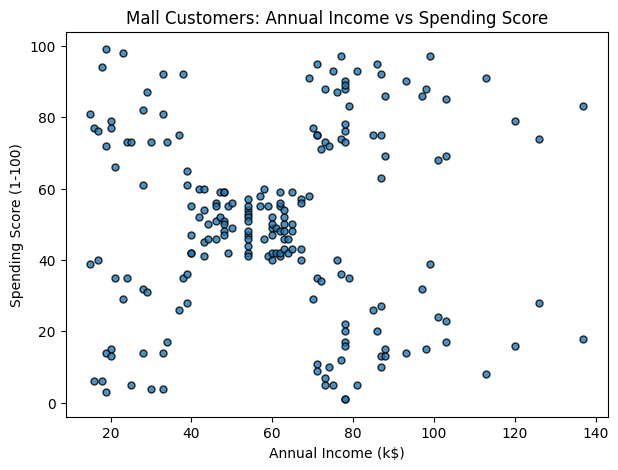

In [2]:
# Select the two clustering features
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].values

# Standardize (mean = 0, std = 1) so both features contribute equally to distances
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled mean:", X_scaled.mean(axis=0).round(3))
print("Scaled std :", X_scaled.std(axis=0).round(3))

# Raw data before clustering
plt.figure(figsize=(7, 5))
plt.scatter(df[features[0]], df[features[1]], s=25, edgecolor="k", alpha=0.8)
plt.xlabel(features[0]); plt.ylabel(features[1])
plt.title("Mall Customers: Annual Income vs Spending Score")
plt.show()

# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

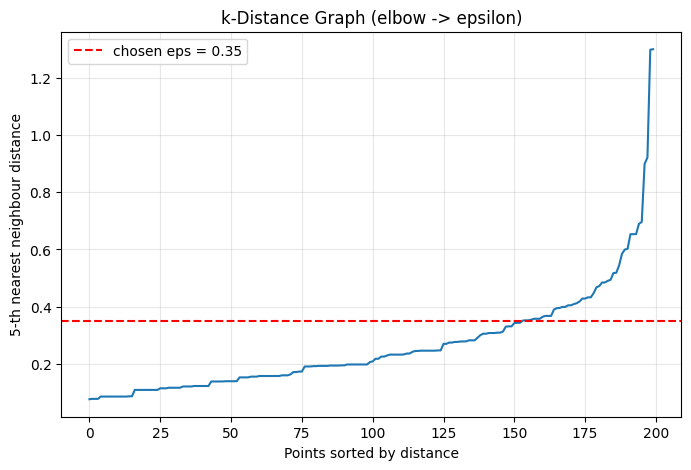

Chosen parameters: eps = 0.35, min_samples = 5


In [3]:
min_samples = 5   # rule of thumb: min_samples >= dimensions + 1 (commonly 4 or 5 for 2-D data)

# Distance of every point to its k-th nearest neighbour (k = min_samples).
# The point itself counts as its own nearest neighbour, so the last column is the k-distance.
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

eps = 0.35   # chosen at the elbow, where the curve starts to rise sharply

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.axhline(eps, color="red", ls="--", label=f"chosen eps = {eps}")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"{min_samples}-th nearest neighbour distance")
plt.title("k-Distance Graph (elbow -> epsilon)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

print(f"Chosen parameters: eps = {eps}, min_samples = {min_samples}")

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

Core points  : 153
Border points: 24
Noise points : 23


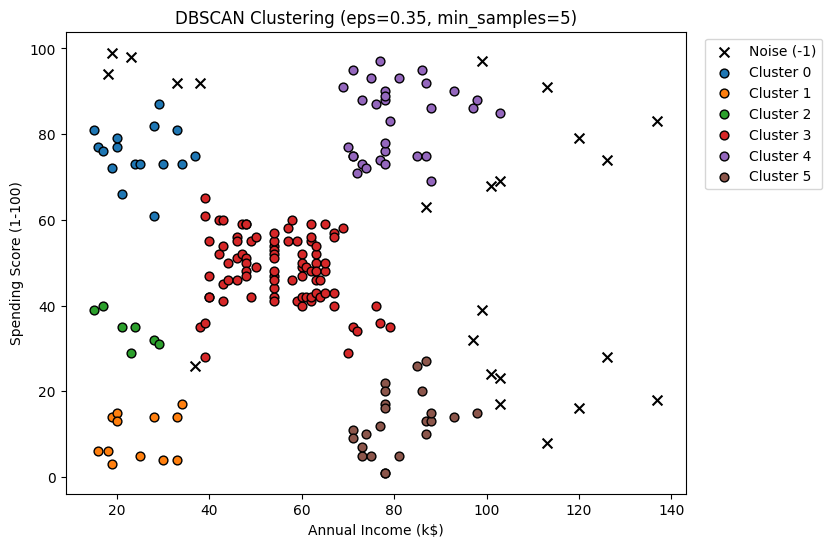

In [4]:
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
labels = dbscan.fit_predict(X_scaled)

# Core / border / noise classification
core_mask = np.zeros(len(labels), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True
noise_mask = labels == -1
border_mask = ~core_mask & ~noise_mask

print("Core points  :", core_mask.sum())
print("Border points:", border_mask.sum())
print("Noise points :", noise_mask.sum())

# Plot clusters (noise = black crosses)
plt.figure(figsize=(8, 6))
for lab in sorted(set(labels)):
    m = labels == lab
    if lab == -1:
        plt.scatter(X[m, 0], X[m, 1], c="k", marker="x", s=50, label="Noise (-1)")
    else:
        plt.scatter(X[m, 0], X[m, 1], s=40, edgecolor="k", label=f"Cluster {lab}")
plt.xlabel(features[0]); plt.ylabel(features[1])
plt.title(f"DBSCAN Clustering (eps={eps}, min_samples={min_samples})")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [5]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())

print("Number of clusters (excluding noise):", n_clusters)
print(f"Noise points: {n_noise} ({n_noise / len(labels) * 100:.1f}% of customers)")
print("\nPoints per label:")
print(pd.Series(labels).value_counts().sort_index())

# Silhouette Score is computed on clustered points only (noise excluded),
# because noise points do not belong to any cluster.
mask = labels != -1
sil = silhouette_score(X_scaled[mask], labels[mask])
print(f"\nSilhouette Score (noise excluded): {sil:.4f}")

Number of clusters (excluding noise): 6
Noise points: 23 (11.5% of customers)

Points per label:
-1    23
 0    16
 1    12
 2     7
 3    88
 4    31
 5    23
Name: count, dtype: int64

Silhouette Score (noise excluded): 0.5577


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

,Customers,Avg_Age,Avg_Income,Avg_Spending
Cluster,,,,
-1,23,34.43,89.26,57.83
0,16,24.81,24.75,75.38
1,12,48.75,24.58,9.58
2,7,36.71,22.43,34.43
3,88,42.88,55.23,48.58
4,31,32.84,80.29,83.19
5,23,41.22,80.96,12.78



Noise points (outliers):


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
7,8,Female,23,18,94
11,12,Female,35,19,99
19,20,Female,35,23,98
33,34,Male,18,33,92
38,39,Female,36,37,26
41,42,Male,24,38,92
169,170,Male,32,87,63
180,181,Female,37,97,32
184,185,Female,41,99,39
185,186,Male,30,99,97


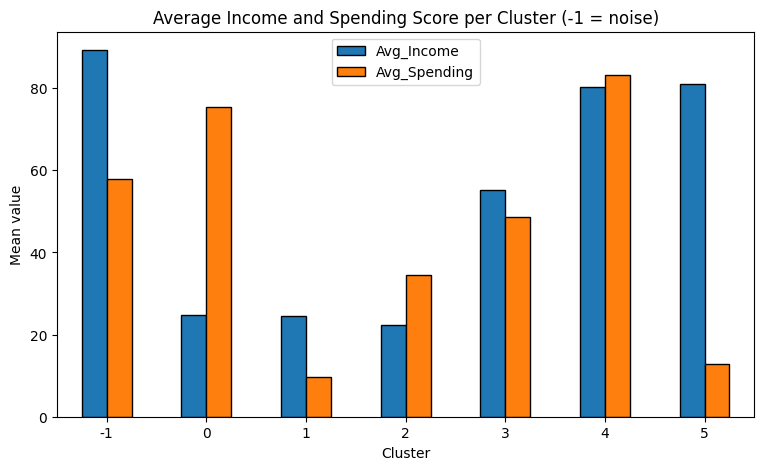

In [6]:
# Append the labels to the original dataset
df["Cluster"] = labels

# Mean statistics and size per cluster (-1 = noise)
cluster_stats = (df.groupby("Cluster")
                   .agg(Customers=("CustomerID", "count"),
                        Avg_Age=("Age", "mean"),
                        Avg_Income=("Annual Income (k$)", "mean"),
                        Avg_Spending=("Spending Score (1-100)", "mean"))
                   .round(2))
display(cluster_stats)

# The detected noise points (spatial outliers)
print("\nNoise points (outliers):")
display(df[df["Cluster"] == -1][["CustomerID", "Gender", "Age", "Annual Income (k$)", "Spending Score (1-100)"]])

# Visual summary of the cluster profiles
cluster_stats[["Avg_Income", "Avg_Spending"]].plot(kind="bar", figsize=(9, 5), edgecolor="k")
plt.title("Average Income and Spending Score per Cluster (-1 = noise)")
plt.xlabel("Cluster"); plt.ylabel("Mean value"); plt.xticks(rotation=0)
plt.show()

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.